
# Анализ влияния сервисного сбора на поведение клиентов T-Банка

## 1. Бизнес-контекст

В сервисе оплаты топлива T-Банка клиенту может назначаться сервисный сбор за заказ. Размер сбора варьируется и принимает несколько фиксированных значений. Для продуктовой команды важно понимать, как размер сервисного сбора связан с активностью пользователей и экономическими показателями сервиса.

Изучение этой зависимости может помочь сформировать гипотезы для дальнейшей настройки тарифов и проведения продуктовых экспериментов.

## 2. Цель исследования

Исследовать связь между размером сервисного сбора и поведением клиентов сервиса оплаты топлива, оценить различия в пользовательской активности и финансовых метриках при разных размерах сбора, а также определить ограничения имеющихся данных.

## 3. Исследовательские вопросы

1. Как распределён сервисный сбор и насколько часто встречаются разные его значения?
2. Связан ли размер сбора с количеством заказов и посещений сервиса?
3. Различаются ли оборот и объём заправленного топлива при разных размерах сбора?
4. Меняется ли наблюдаемая зависимость в разных пользовательских сегментах?
5. Сохраняются ли обнаруженные закономерности при учёте повторных наблюдений одного клиента и других доступных факторов?

## 4. Проверяемые гипотезы

**H1. Пользовательская активность.** Размер сервисного сбора связан с количеством заказов клиента за неделю.

**H2. Посещения сервиса.** Размер сервисного сбора связан с количеством посещений сервиса за неделю.

**H3. Экономические метрики.** Размер сервисного сбора связан с недельным оборотом и объёмом заправленного топлива.

**H4. Пользовательские сегменты.** Связь между размером сбора и пользовательскими метриками различается в зависимости от доступных характеристик клиента или условий обслуживания.

Гипотезы сформулированы как проверяемые предположения. Направление, величина и статистическая значимость обнаруженных связей будут определены в ходе анализа.

## 5. Данные и единица наблюдения

В исследовании используется датасет из учебного кейса T-Банка, опубликованного на странице соревнования ДАНО НИУ ВШЭ.

Единица наблюдения — клиент за конкретную неделю. Данные содержат идентификатор клиента, неделю наблюдения, размер сервисного сбора, показатели заказов, оборота, посещений и объёма заправленного топлива, а также доступные характеристики клиента и условия обслуживания.

## 6. Методология и ограничения

Исследование включает проверку качества данных, разведочный анализ, сравнение пользовательских метрик, статистическую проверку гипотез и дополнительные проверки устойчивости результатов.

Наблюдательные данные сами по себе не позволяют установить причинно-следственную связь. Клиенты с разными размерами сервисного сбора могут изначально отличаться по активности, подписке, условиям обслуживания и другим характеристикам. Кроме того, один клиент может присутствовать в данных за несколько недель.

Поэтому результаты будут интерпретироваться как обнаруженные зависимости, если дизайн данных не позволяет обосновать более сильные причинные выводы. Возможность учёта повторных наблюдений и смешивающих факторов будет оценена отдельно.

Период наблюдений, качество признаков, доступность данных для сегментации и применимость статистических методов будут уточнены на этапе подготовки данных.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 6)

RANDOM_STATE = 42

print("Библиотеки успешно импортированы.")
print(f"pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")

Библиотеки успешно импортированы.
pandas: 3.0.6
NumPy: 2.5.3


In [5]:
from pathlib import Path

# Путь к исходному датасету
DATA_PATH = Path("../data/fuel_data.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Файл не найден: {DATA_PATH.resolve()}\n"
        "Проверь путь к CSV-файлу."
    )

df = pd.read_csv(DATA_PATH)

print(f"Данные загружены: {df.shape[0]:,} строк, {df.shape[1]} столбцов")

Данные загружены: 448,132 строк, 18 столбцов


In [11]:
print("Размер датасета:", df.shape)

print("\nНазвания столбцов:")
display(pd.DataFrame({"column": df.columns}))

print("\nТипы данных и количество непустых значений:")
df.info()

Размер датасета: (448132, 19)

Названия столбцов:


,column
0,week
1,party_rk
2,service_fee_amt
3,gmv
4,orders_cnt
5,bundle_name
6,cashback_category
7,platform
8,liters
9,first_order_date



Типы данных и количество непустых значений:
<class 'pandas.DataFrame'>
RangeIndex: 448132 entries, 0 to 448131
Data columns (total 19 columns):
 #   Column              Non-Null Count   Dtype              
---  ------              --------------   -----              
 0   week                448132 non-null  str                
 1   party_rk            448132 non-null  int64              
 2   service_fee_amt     448132 non-null  int64              
 3   gmv                 448132 non-null  float64            
 4   orders_cnt          448132 non-null  float64            
 5   bundle_name         448132 non-null  str                
 6   cashback_category   448132 non-null  float64            
 7   platform            448132 non-null  str                
 8   liters              448132 non-null  float64            
 9   first_order_date    448132 non-null  str                
 10  entries_cnt         442770 non-null  float64            
 11  region              0 non-null       float64

In [7]:
missing_report = (
    pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_share_pct": df.isna().mean() * 100,
        "non_missing_count": df.notna().sum(),
        "dtype": df.dtypes.astype(str),
    })
    .sort_values("missing_share_pct", ascending=False)
    .round(2)
)

display(missing_report)

,missing_count,missing_share_pct,non_missing_count,dtype
region,448132,100.000,0,float64
education_level_cd,382807,85.420,65325,str
job_title,380250,84.850,67882,str
marital_status_cd,371033,82.800,77099,str
children_cnt,349339,77.950,98793,float64
gender_cd,319930,71.390,128202,str
age,319841,71.370,128291,float64
entries_cnt,5362,1.200,442770,float64
party_rk,0,0.000,448132,int64
week,0,0.000,448132,str


In [8]:
full_duplicates = df.duplicated().sum()

print(f"Полностью дублирующихся строк: {full_duplicates:,}")

key_columns = ["party_rk", "week"]

missing_key_values = df[key_columns].isna().any(axis=1).sum()
duplicate_keys = df.duplicated(subset=key_columns, keep=False).sum()

print(f"Строк с пропусками в ключевых полях: {missing_key_values:,}")
print(f"Строк, входящих в повторяющиеся пары клиент-неделя: {duplicate_keys:,}")

if duplicate_keys > 0:
    print("\nПримеры повторяющихся ключей:")
    display(
        df.loc[
            df.duplicated(subset=key_columns, keep=False),
            key_columns + ["service_fee_amt", "orders_cnt", "gmv"]
        ].sort_values(key_columns).head(10)
    )

Полностью дублирующихся строк: 0
Строк с пропусками в ключевых полях: 0
Строк, входящих в повторяющиеся пары клиент-неделя: 0


In [9]:
main_metrics = [
    "service_fee_amt",
    "gmv",
    "orders_cnt",
    "entries_cnt",
    "liters",
]

display(df[main_metrics].describe().T.round(3))

,count,mean,std,min,25%,50%,75%,max
service_fee_amt,"448,132.000",21.606,19.476,0.000,0.000,19.000,23.000,99.000
gmv,"448,132.000","2,505.952","1,903.173",0.550,"1,498.920","2,085.805","2,999.440","200,585.990"
orders_cnt,"448,132.000",1.363,0.785,1.000,1.000,1.000,1.000,19.000
entries_cnt,"442,770.000",2.578,1.576,1.000,2.000,2.000,3.000,19.000
liters,"448,132.000",41.100,29.753,0.000,24.760,35.180,49.020,"2,799.690"


In [10]:
df["week_dt"] = pd.to_datetime(df["week"], utc=True, errors="coerce")

print("Некорректных дат:", df["week_dt"].isna().sum())
print("Начало периода:", df["week_dt"].min())
print("Конец периода:", df["week_dt"].max())
print("Количество уникальных недель:", df["week_dt"].nunique())
print("Количество уникальных клиентов:", df["party_rk"].nunique())

weeks_per_client = df.groupby("party_rk")["week_dt"].nunique()

display(
    weeks_per_client.describe()
    .to_frame("weeks_per_client")
    .round(2)
)

Некорректных дат: 0
Начало периода: 2025-03-30 21:00:00+00:00
Конец периода: 2025-05-25 21:00:00+00:00
Количество уникальных недель: 9
Количество уникальных клиентов: 99877


,weeks_per_client
count,"99,877.000"
mean,4.490
std,1.720
min,1.000
25%,3.000
50%,4.000
75%,5.000
max,9.000



## 1.1. Результаты первичного аудита данных

### Общая характеристика выборки

Исходный датасет содержит 448 132 наблюдения и 18 исходных признаков. После преобразования временного признака для анализа в таблицу был добавлен столбец `week_dt`, содержащий дату в формате datetime.
В данных представлены 99 877 уникальных клиентов, наблюдаемых на протяжении девяти недель. В среднем на одного клиента приходится 4,49 недельных наблюдения; медианное значение составляет 4 недели.

### Качество и полнота данных

В ходе проверки не обнаружено полностью дублирующихся строк. Пара признаков `party_rk` и `week` уникальна для каждой записи, пропуски в этих ключевых полях отсутствуют. Это позволяет использовать пару «клиент — неделя» в качестве идентификатора наблюдения.
Пропуски сосредоточены преимущественно в демографических характеристиках. Признак `region` полностью состоит из пропущенных значений. Доля пропусков в `age` и `gender_cd` составляет около 71%, в `education_level_cd` — 85,42%, в `job_title` — 84,85%, в `marital_status_cd` — 82,80%, в `children_cnt` — 77,95%.
В признаке `entries_cnt` отсутствуют 1,20% значений. При дальнейшем анализе необходимо учитывать эти пропуски и не подменять отсутствующие данные нулями без дополнительного обоснования.

### Особенности основных показателей

Сервисный сбор принимает дискретные значения в диапазоне от 0 до 99 рублей. Среднее значение составляет 19,48 рубля, медиана — 19 рублей. Распределение сбора и численность отдельных групп будут дополнительно изучены в следующиъ этапах.
Средний недельный оборот (`gmv`) составляет 2 505,95 условной единицы, медиана — 2 085,81. Среднее количество заказов (`orders_cnt`) равно 1,36 при медиане 1. Среднее количество посещений (`entries_cnt`) составляет 2,58, медиана - 2. Средний объём топлива (`liters`) равен 41,10 литра при медиане 35,18 литра.
Максимальные значения оборота и объёма топлива существенно превышают соответствующие медианы. Эти наблюдения требуют дополнительной проверки, однако на данном этапе не исключаются из выборки, поскольку высокое значение само по себе не свидетельствует об ошибке.

### Ограничения исследования

Период наблюдения охватывает девять недель, поэтому исследование ориентировано прежде всего на краткосрочное поведение клиентов. Доступность демографических признаков ограничена значительным количеством пропусков.
Кроме того, один клиент может присутствовать в нескольких недельных наблюдениях. Такие записи нельзя автоматически считать независимыми при проведении статистических тестов.
Наконец, имеющиеся данные являются наблюдательными. Без подтверждения случайного назначения сервисного сбора обнаруженные различия нельзя однозначно интерпретировать как причинный эффект размера сбора на поведение клиентов.

### Вывод по результатам аудита

Датасет содержит значительный объём наблюдений и позволяет исследовать связь между размером сервисного сбора и недельными показателями активности клиентов. Ключевые поля заполнены, повторяющиеся пары «клиент - неделя» не обнаружены.
Перед проверкой исследовательских гипотез необходимо изучить распределение сервисного сбора, динамику метрик по неделям и характер экстремальных значений. Эти особенности будут учтены при выборе статистических методов и интерпретации результатов.



# 2. Исследовательский анализ данных (EDA)

Цель данного этапа — изучить структуру данных, распределения ключевых показателей и различия между наблюдениями с разными размерами сервисного сбора.

Сначала анализируется частота встречаемости каждого значения сбора. Затем рассматриваются недельная динамика показателей и распределения пользовательских метрик. Полученные результаты помогут определить особенности выборки и подготовить данные к проверке исследовательских гипотез.


,service_fee_amt,observations,share_pct
0,0,"118,501",26.44%
1,19,"160,921",35.91%
2,23,"66,015",14.73%
3,29,"23,049",5.14%
4,39,"24,136",5.39%
5,49,"16,524",3.69%
6,59,"15,835",3.53%
7,69,"15,295",3.41%
8,79,"2,680",0.60%
9,89,"2,663",0.59%


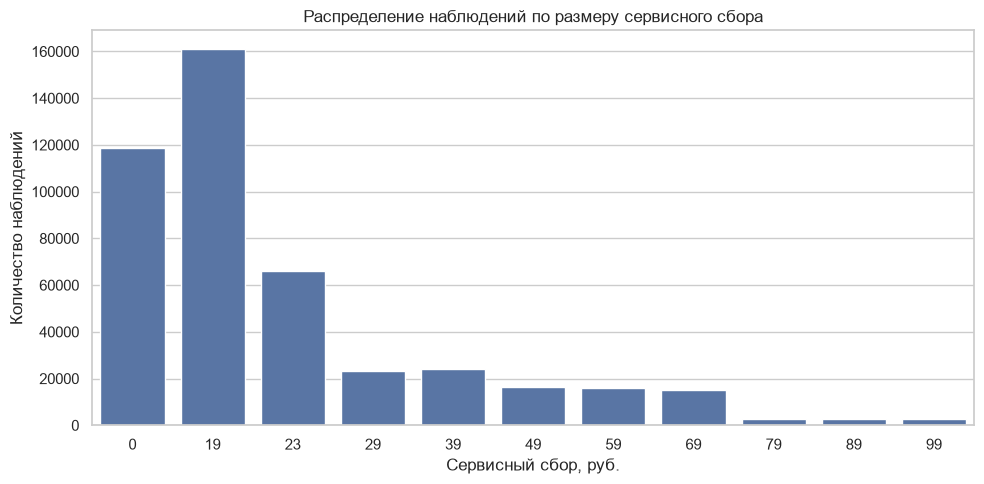

In [14]:
fee_distribution = (
    df.groupby("service_fee_amt")
    .size()
    .rename("observations")
    .reset_index()
    .sort_values("service_fee_amt")
)

fee_distribution["share_pct"] = (
    fee_distribution["observations"] / len(df) * 100
)

display(
    fee_distribution.style.format({
        "observations": "{:,.0f}",
        "share_pct": "{:.2f}%"
    })
)

fig, ax = plt.subplots(figsize=(10, 5))

sns.barplot(
    data=fee_distribution,
    x="service_fee_amt",
    y="observations",
    ax=ax
)

ax.set_title("Распределение наблюдений по размеру сервисного сбора")
ax.set_xlabel("Сервисный сбор, руб.")
ax.set_ylabel("Количество наблюдений")
ax.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.show()


### 2.1. Распределение сервисного сбора

Распределение наблюдений по размеру сервисного сбора является неравномерным. Наиболее распространённый сбор составляет 19 рублей: на него приходится 35,91% наблюдений. Нулевой сбор встречается в 26,44% случаев, а сбор в размере 23 рублей — в 14,73%.

В совокупности эти три группы составляют около 77,1% выборки. В то же время значения 79, 89 и 99 рублей представлены значительно реже: доля каждого из них не превышает 0,60%.

Таким образом, выборка характеризуется существенным различием в численности групп по размеру сбора. Это необходимо учитывать при сравнении пользовательских метрик: оценки для редких групп могут иметь большую статистическую неопределённость.

На данном этапе установлена только структура распределения сбора. О наличии и направлении связи между размером сбора и активностью клиентов можно будет судить после анализа соответствующих показателей.


In [15]:
weekly_metrics = (
    df.groupby("week_dt")
    .agg(
        observations=("party_rk", "size"),
        unique_clients=("party_rk", "nunique"),
        mean_fee=("service_fee_amt", "mean"),
        median_fee=("service_fee_amt", "median"),
        mean_orders=("orders_cnt", "mean"),
        mean_entries=("entries_cnt", "mean"),
        mean_gmv=("gmv", "mean"),
        total_gmv=("gmv", "sum"),
        mean_liters=("liters", "mean"),
    )
    .reset_index()
    .sort_values("week_dt")
)

display(
    weekly_metrics.style
    .hide(axis="index")
    .format({
        "observations": "{:,.0f}",
        "unique_clients": "{:,.0f}",
        "mean_fee": "{:.2f}",
        "median_fee": "{:.2f}",
        "mean_orders": "{:.3f}",
        "mean_entries": "{:.3f}",
        "mean_gmv": "{:,.2f}",
        "total_gmv": "{:,.2f}",
        "mean_liters": "{:.2f}",
    })
)

week_dt,observations,unique_clients,mean_fee,median_fee,mean_orders,mean_entries,mean_gmv,total_gmv,mean_liters
2025-03-30 21:00:00+00:00,"44,492","44,492",18.17,23.00,1.276,2.537,"2,323.48","103,376,291.77",38.33
2025-04-06 21:00:00+00:00,"43,474","43,474",36.78,29.00,1.348,2.474,"2,474.52","107,577,252.52",40.76
2025-04-13 21:00:00+00:00,"43,333","43,333",39.62,39.00,1.337,2.470,"2,495.37","108,131,989.78",40.95
2025-04-20 21:00:00+00:00,"43,977","43,977",35.74,29.00,1.342,2.523,"2,510.71","110,413,657.84",41.20
2025-04-27 21:00:00+00:00,"54,166","54,166",20.04,19.00,1.383,2.661,"2,562.81","138,817,417.54",41.99
2025-05-04 21:00:00+00:00,"55,467","55,467",13.07,19.00,1.415,2.736,"2,572.52","142,689,852.58",42.17
2025-05-11 21:00:00+00:00,"55,249","55,249",13.38,19.00,1.372,2.596,"2,510.73","138,715,165.98",41.19
2025-05-18 21:00:00+00:00,"53,356","53,356",13.40,19.00,1.378,2.560,"2,522.62","134,596,895.13",41.26
2025-05-25 21:00:00+00:00,"54,618","54,618",13.21,19.00,1.386,2.580,"2,539.07","138,678,850.12",41.46


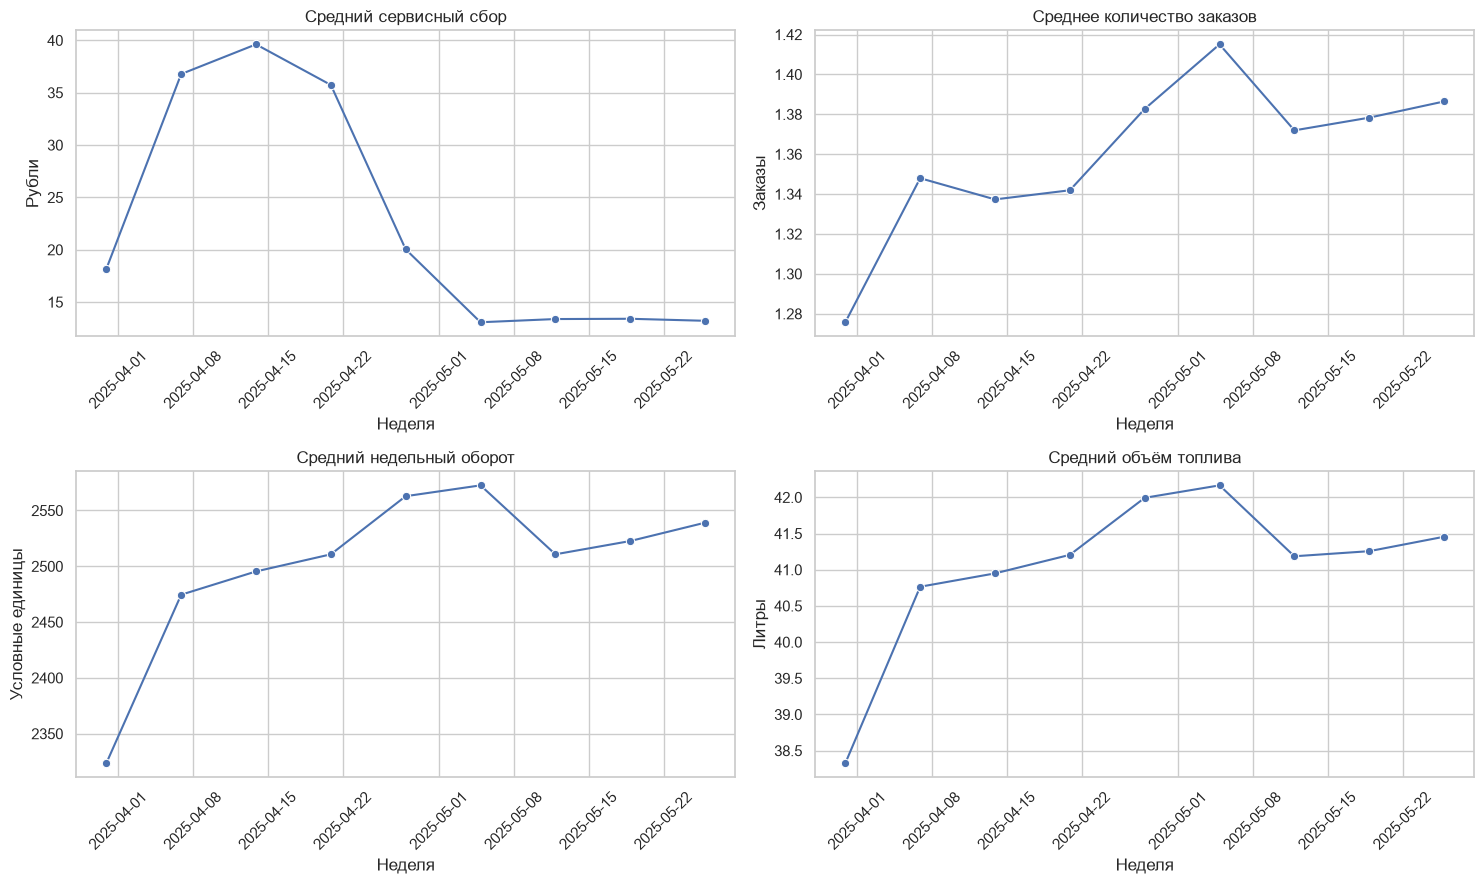

In [16]:
fig, axes = plt.subplots(2, 2, figsize=(15, 9))

plots = [
    ("mean_fee", "Средний сервисный сбор", "Рубли"),
    ("mean_orders", "Среднее количество заказов", "Заказы"),
    ("mean_gmv", "Средний недельный оборот", "Условные единицы"),
    ("mean_liters", "Средний объём топлива", "Литры"),
]

for ax, (column, title, ylabel) in zip(axes.flat, plots):
    sns.lineplot(
        data=weekly_metrics,
        x="week_dt",
        y=column,
        marker="o",
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Неделя")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


### 2.2. Динамика показателей по неделям

В течение рассматриваемого периода наблюдается существенная динамика среднего размера сервисного сбора. В начале периода он составлял 18,17 рубля, затем увеличился до максимального значения 39,62 рубля на неделе, начинающейся 13 апреля 2025 года. В последующие недели средний сбор снизился и к концу периода находился на уровне около 13 рублей.

Среднее количество заказов за неделю изменялось от 1,276 до 1,415, а средний оборот — от 2 323,48 до 2 572,52 условной единицы. Средний объём топлива увеличился с 38,33 до значений около 41–42 литров.

Число наблюдений также менялось: в начале периода оно составляло около 43–44 тысяч в неделю, а позднее превышало 53 тысячи. Поэтому динамику суммарного оборота необходимо интерпретировать с учётом изменения количества наблюдений; для сравнения недель более информативны средние показатели.

Выявленная динамика указывает на необходимость учитывать временной фактор при дальнейшем анализе связи сервисного сбора с поведением клиентов. По этим описательным данным нельзя определить, вызваны ли изменения активности изменением сбора или другими факторами, связанными с периодом наблюдения.


In [18]:
metrics = ["gmv", "orders_cnt", "entries_cnt", "liters"]

distribution_report = (
    df[metrics]
    .describe(percentiles=[0.5, 0.75, 0.90, 0.95, 0.99])
    .T
    .rename(columns={
        "50%": "median",
        "75%": "p75",
        "90%": "p90",
        "95%": "p95",
        "99%": "p99",
    })
)

display(distribution_report.round(3))

,count,mean,std,min,median,p75,p90,p95,p99,max
gmv,"448,132.000","2,505.952","1,903.173",0.550,"2,085.805","2,999.440","4,331.452","5,499.610","9,041.692","200,585.990"
orders_cnt,"448,132.000",1.363,0.785,1.000,1.000,1.000,2.000,3.000,5.000,19.000
entries_cnt,"442,770.000",2.578,1.576,1.000,2.000,3.000,4.000,6.000,8.000,19.000
liters,"448,132.000",41.100,29.753,0.000,35.180,49.020,69.980,89.630,146.260,"2,799.690"


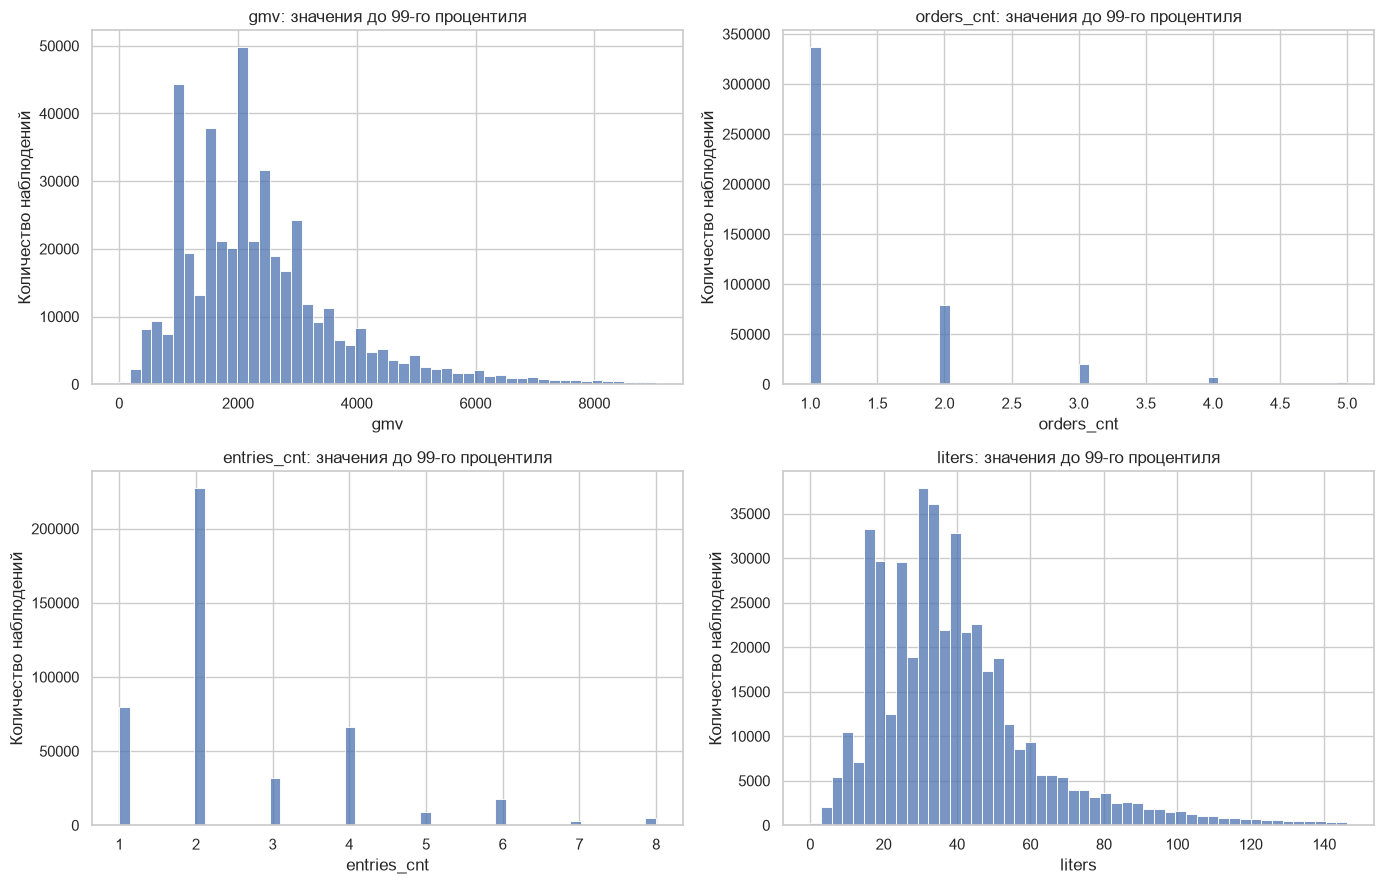

In [20]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for column, ax in zip(metrics, axes.flat):
    upper_limit = df[column].quantile(0.99)

    sns.histplot(
        data=df.loc[df[column] <= upper_limit],
        x=column,
        bins=50,
        ax=ax
    )

    ax.set_title(f"{column}: значения до 99-го процентиля")
    ax.set_xlabel(column)
    ax.set_ylabel("Количество наблюдений")

plt.tight_layout()
plt.show()


### 2.3. Распределения основных пользовательских метрик

Распределения оборота и объёма топлива характеризуются правосторонней асимметрией: средние значения превышают медианы, а максимальные значения значительно выше 99-го процентиля. Это указывает на наличие небольшого числа наблюдений с особенно высокими показателями.

Количество заказов за неделю также распределено неравномерно. Медиана и 75-й процентиль равны одному заказу, а 90-й процентиль составляет два заказа. Следовательно, большинство недельных наблюдений характеризуется низким числом заказов, тогда как более высокие значения встречаются реже.

Количество посещений сервиса имеет медиану 2 и 99-й процентиль 8. Для оборота и объёма топлива разрыв между 99-м процентилем и максимумом особенно велик, поэтому экстремальные наблюдения могут заметно влиять на средние значения.

С учётом этих особенностей дальнейшее сравнение групп будет включать как средние, так и медианные показатели. При статистической проверке гипотез также необходимо учитывать асимметрию распределений, неравномерную численность групп и повторные наблюдения одних и тех же клиентов.

На этапе разведочного анализа экстремальные значения не удалялись. Их влияние будет дополнительно оценено при проверке устойчивости результатов.


In [21]:
fee_comparison = (
    df.groupby("service_fee_amt")
    .agg(
        observations=("party_rk", "size"),
        unique_clients=("party_rk", "nunique"),

        mean_orders=("orders_cnt", "mean"),
        median_orders=("orders_cnt", "median"),

        mean_entries=("entries_cnt", "mean"),
        median_entries=("entries_cnt", "median"),

        mean_gmv=("gmv", "mean"),
        median_gmv=("gmv", "median"),

        mean_liters=("liters", "mean"),
        median_liters=("liters", "median"),
    )
    .reset_index()
    .sort_values("service_fee_amt")
)

display(
    fee_comparison.style
    .hide(axis="index")
    .format({
        "service_fee_amt": "{:.0f}",
        "observations": "{:,.0f}",
        "unique_clients": "{:,.0f}",
        "mean_orders": "{:.3f}",
        "median_orders": "{:.0f}",
        "mean_entries": "{:.3f}",
        "median_entries": "{:.0f}",
        "mean_gmv": "{:,.2f}",
        "median_gmv": "{:,.2f}",
        "mean_liters": "{:.2f}",
        "median_liters": "{:.2f}",
    })
)

service_fee_amt,observations,unique_clients,mean_orders,median_orders,mean_entries,median_entries,mean_gmv,median_gmv,mean_liters,median_liters
0,"118,501","45,645",1.356,1,2.714,2,"2,364.62","1,999.34",38.70,33.80
19,"160,921","60,773",1.404,1,2.599,2,"2,629.29","2,199.60",43.18,36.97
23,"66,015","40,682",1.311,1,2.492,2,"2,413.26","2,022.24",39.67,35.00
29,"23,049","11,256",1.376,1,2.514,2,"2,423.52","1,999.88",39.94,34.72
39,"24,136","11,871",1.326,1,2.428,2,"2,571.81","2,190.90",41.94,36.60
49,"16,524","8,778",1.334,1,2.435,2,"2,550.54","2,164.49",41.95,36.11
59,"15,835","8,452",1.331,1,2.435,2,"2,560.92","2,167.04",41.82,36.04
69,"15,295","8,238",1.336,1,2.414,2,"2,578.05","2,198.78",42.18,36.93
79,"2,680","1,863",1.350,1,2.415,2,"2,611.21","2,215.00",42.60,37.28
89,"2,663","1,842",1.321,1,2.424,2,"2,566.87","2,190.00",41.80,36.65


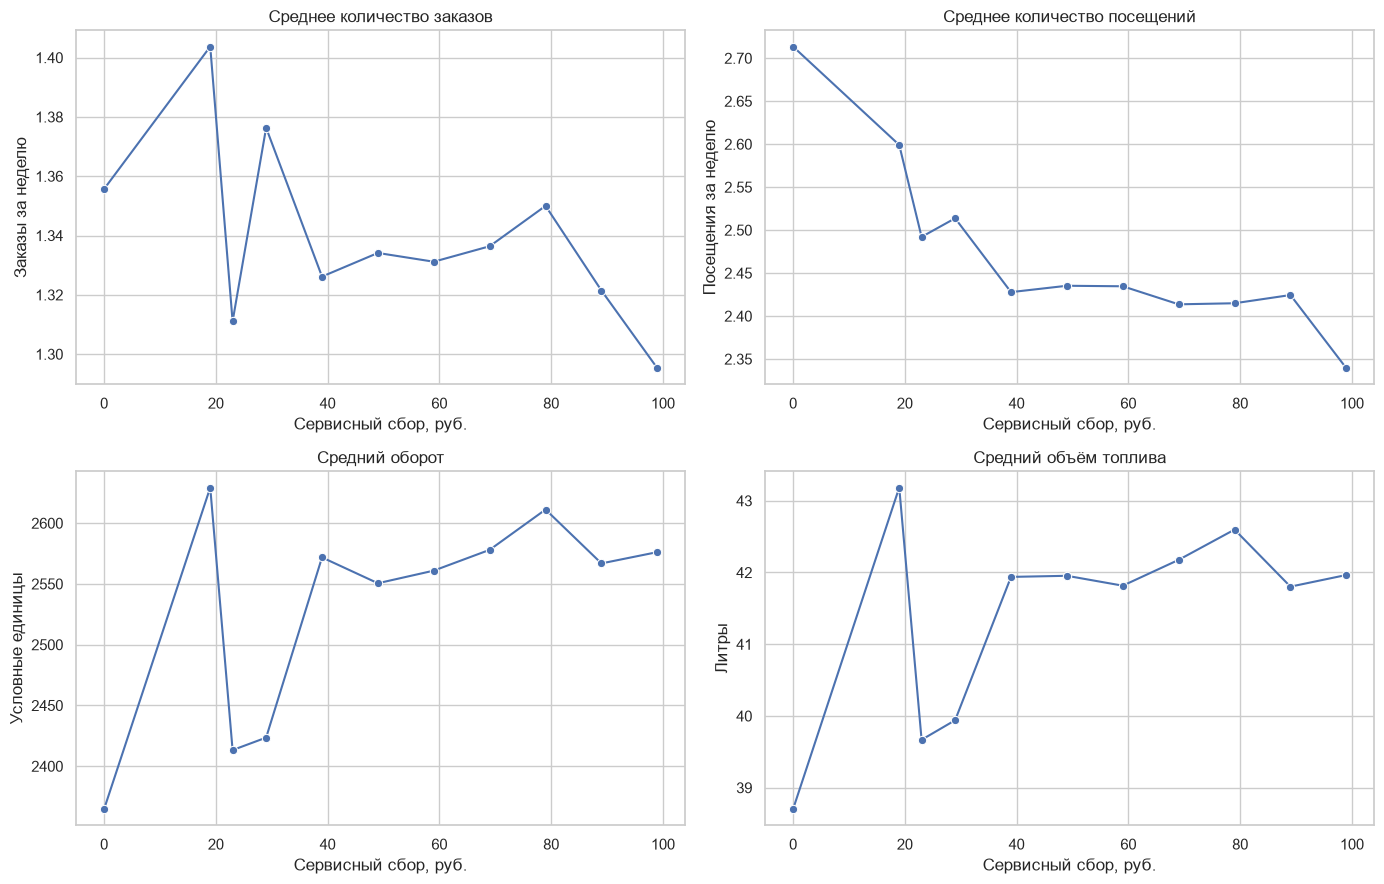

In [22]:
plot_metrics = [
    ("mean_orders", "Среднее количество заказов", "Заказы за неделю"),
    ("mean_entries", "Среднее количество посещений", "Посещения за неделю"),
    ("mean_gmv", "Средний оборот", "Условные единицы"),
    ("mean_liters", "Средний объём топлива", "Литры"),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for ax, (column, title, ylabel) in zip(axes.flat, plot_metrics):
    sns.lineplot(
        data=fee_comparison,
        x="service_fee_amt",
        y=column,
        marker="o",
        ax=ax
    )
    ax.set_title(title)
    ax.set_xlabel("Сервисный сбор, руб.")
    ax.set_ylabel(ylabel)

plt.tight_layout()
plt.show()

## 2.4.1. Промежуточные выводы по сравнению метрик

Сравнение пользовательских метрик в зависимости от размера сервисного сбора показало следующие особенности:

1. **Количество заказов относительно стабильно.** Среднее число заказов за неделю находится в диапазоне от 1,295 до 1,404, а медиана во всех группах равна одному заказу. Выраженной монотонной зависимости между размером сбора и количеством заказов на данном этапе не наблюдается.

2. **Количество посещений несколько ниже в группах с высоким сбором.** Среднее число посещений составляет 2,714 при нулевом сборе и 2,339 при сборе 99 рублей. Однако снижение не является равномерным, поэтому делать вывод о прямой зависимости преждевременно.

3. **Оборот и объём топлива не демонстрируют устойчивого снижения с ростом сбора.** Наибольшие средние значения обоих показателей наблюдаются при сборе 19 рублей. В остальных группах значения колеблются, не формируя очевидной линейной закономерности.

4. **Группы различаются по объёму данных.** Наиболее распространённые значения сбора представлены большим количеством наблюдений, тогда как сборы 79, 89 и 99 рублей встречаются значительно реже. Это необходимо учитывать при дальнейшем сравнении групп.

Следует отметить, что представленные результаты носят описательный характер. Они не позволяют утверждать, что изменение сервисного сбора вызывает изменение поведения клиентов. На наблюдаемые различия могут влиять состав клиентских групп, время наблюдения и другие факторы. Кроме того, один клиент может присутствовать в нескольких группах в разные недели.

**Промежуточный итог:** на основании описательной статистики не выявлено однозначной монотонной связи между размером сервисного сбора и основными пользовательскими метриками. Для дальнейших выводов необходимо исследовать изменения сбора внутри одного клиента и проверить статистическую устойчивость обнаруженных различий.

In [23]:
# Сколько разных значений сервисного сбора встречалось у каждого клиента
client_fee_profile = (
    df.groupby("party_rk")
    .agg(
        weeks_observed=("week_dt", "nunique"),
        unique_fee_values=("service_fee_amt", "nunique"),
        min_fee=("service_fee_amt", "min"),
        max_fee=("service_fee_amt", "max"),
    )
    .reset_index()
)

# Классифицируем клиентов по изменчивости сбора
client_fee_profile["fee_pattern"] = np.where(
    client_fee_profile["unique_fee_values"] == 1,
    "Сбор не менялся",
    "Сбор менялся"
)

fee_stability = (
    client_fee_profile["fee_pattern"]
    .value_counts()
    .rename_axis("fee_pattern")
    .reset_index(name="clients")
)

fee_stability["share_pct"] = (
    fee_stability["clients"] / len(client_fee_profile) * 100
)

display(
    fee_stability.style
    .hide(axis="index")
    .format({
        "clients": "{:,.0f}",
        "share_pct": "{:.2f}%"
    })
)

print(
    "Всего уникальных клиентов:",
    f"{client_fee_profile['party_rk'].nunique():,}"
)

print(
    "Клиентов, наблюдавшихся более одной недели:",
    f"{(client_fee_profile['weeks_observed'] > 1).sum():,}"
)

print(
    "Клиентов с изменением сбора:",
    f"{(client_fee_profile['unique_fee_values'] > 1).sum():,}"
)

fee_pattern,clients,share_pct
Сбор менялся,"69,170",69.26%
Сбор не менялся,"30,707",30.74%


Всего уникальных клиентов: 99,877
Клиентов, наблюдавшихся более одной недели: 98,830
Клиентов с изменением сбора: 69,170


In [24]:
# Рассмотрим клиентов, у которых сбор менялся
clients_with_fee_changes = client_fee_profile.loc[
    client_fee_profile["unique_fee_values"] > 1
].copy()

clients_with_fee_changes["fee_range"] = (
    clients_with_fee_changes["max_fee"]
    - clients_with_fee_changes["min_fee"]
)

print("Распределение числа разных значений сбора на клиента:")
display(
    client_fee_profile["unique_fee_values"]
    .value_counts()
    .sort_index()
    .rename_axis("unique_fee_values")
    .reset_index(name="clients")
    .style.hide(axis="index")
    .format({"clients": "{:,.0f}"})
)

print("\nРазмах сбора у клиентов, у которых он менялся:")
display(
    clients_with_fee_changes["fee_range"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9])
    .to_frame("fee_range_rub")
    .round(2)
)

Распределение числа разных значений сбора на клиента:


unique_fee_values,clients
1,"30,707"
2,"40,294"
3,"25,644"
4,"3,223"
5,9



Размах сбора у клиентов, у которых он менялся:


,fee_range_rub
count,"69,170.000"
mean,33.880
std,21.800
min,4.000
25%,19.000
50%,29.000
75%,49.000
90%,69.000
max,99.000


## 2.5. Изменчивость сервисного сбора внутри клиентских групп

Анализ динамики сервисного сбора на уровне отдельных клиентов показал, что у большинства пользователей его значение менялось в течение периода наблюдения.

Из 99 877 уникальных клиентов у 69 170 (69,26%) зафиксировано более одного значения сервисного сбора. У остальных 30 707 клиентов (30,74%) сбор оставался неизменным. При этом 98 830 клиентов наблюдались более одной недели, поэтому изменение сбора можно анализировать на протяжении нескольких периодов.

Наиболее распространённая ситуация — два или три разных значения сбора на одного клиента. У 40 294 клиентов зафиксировано два значения, у 25 644 — три. Четыре значения встречались у 3 223 клиентов, а пять — у девяти клиентов.

Среди пользователей, у которых сбор менялся, медианный размах между максимальным и минимальным значениями составил 29 рублей. У 25% таких клиентов размах не превышал 19 рублей, а у 75% — 49 рублей.

**Промежуточный вывод:** данные позволяют перейти к анализу изменений пользовательских метрик при разных значениях сервисного сбора у одного и того же клиента. Такой подход поможет отделить внутриклиентские изменения от постоянных различий между пользователями. Однако даже при сравнении одного клиента с самим собой необходимо учитывать временные факторы и другие изменения условий обслуживания. Наличие изменений сбора само по себе не доказывает причинно-следственную связь с поведением клиента.

In [25]:
# Оставляем клиентов, у которых сервисный сбор менялся
changing_client_ids = client_fee_profile.loc[
    client_fee_profile["unique_fee_values"] > 1,
    "party_rk"
]

df_changing = df[df["party_rk"].isin(changing_client_ids)].copy()

# Средние метрики одного клиента при каждом значении сбора
client_fee_metrics = (
    df_changing
    .groupby(["party_rk", "service_fee_amt"], as_index=False)
    .agg(
        weeks=("week_dt", "nunique"),
        mean_orders=("orders_cnt", "mean"),
        mean_entries=("entries_cnt", "mean"),
        mean_gmv=("gmv", "mean"),
        mean_liters=("liters", "mean"),
    )
)

print("Клиентов с изменявшимся сбором:", f"{len(changing_client_ids):,}")
print("Строк в таблице клиент-сбор:", f"{len(client_fee_metrics):,}")
print(
    "Уникальных клиентов в итоговой таблице:",
    f"{client_fee_metrics['party_rk'].nunique():,}"
)

display(client_fee_metrics.head(10))

Клиентов с изменявшимся сбором: 69,170
Строк в таблице клиент-сбор: 170,457
Уникальных клиентов в итоговой таблице: 69,170


,party_rk,service_fee_amt,weeks,mean_orders,mean_entries,mean_gmv,mean_liters
0,12103,0,1,1.000,2.000,573.250,9.980
1,12103,19,2,1.000,2.000,"2,196.400",40.000
2,12103,29,2,1.000,2.000,"2,196.400",39.295
3,14045,0,1,1.000,2.000,"1,373.440",21.670
4,14045,19,1,2.000,4.000,"3,907.280",62.630
5,14045,23,1,1.000,2.000,"2,553.580",41.280
6,14045,69,2,1.500,3.000,"3,413.115",55.290
7,15150,0,1,1.000,2.000,"1,235.180",19.990
8,15150,19,2,4.000,6.000,"9,448.060",149.160
9,15150,29,1,1.000,2.000,"2,470.980",39.990


In [26]:
metrics_to_compare = {
    "mean_orders": "Количество заказов",
    "mean_entries": "Количество посещений",
    "mean_gmv": "Оборот",
    "mean_liters": "Объём топлива",
}

# Средние метрики каждого клиента по всем его наблюдениям
client_baselines = (
    df_changing
    .groupby("party_rk")
    .agg(
        baseline_orders=("orders_cnt", "mean"),
        baseline_entries=("entries_cnt", "mean"),
        baseline_gmv=("gmv", "mean"),
        baseline_liters=("liters", "mean"),
    )
    .reset_index()
)

within_client = client_fee_metrics.merge(
    client_baselines,
    on="party_rk",
    how="left",
    validate="many_to_one"
)

within_client["orders_diff"] = (
    within_client["mean_orders"] - within_client["baseline_orders"]
)
within_client["entries_diff"] = (
    within_client["mean_entries"] - within_client["baseline_entries"]
)
within_client["gmv_diff"] = (
    within_client["mean_gmv"] - within_client["baseline_gmv"]
)
within_client["liters_diff"] = (
    within_client["mean_liters"] - within_client["baseline_liters"]
)

# Каждое наблюдение клиент-сбор получает одинаковый вес внутри клиента,
# а затем каждому клиенту присваивается одинаковый вес в итоговой таблице.
within_client_summary = (
    within_client
    .groupby("service_fee_amt")
    .agg(
        clients=("party_rk", "nunique"),
        orders_diff=("orders_diff", "mean"),
        entries_diff=("entries_diff", "mean"),
        gmv_diff=("gmv_diff", "mean"),
        liters_diff=("liters_diff", "mean"),
    )
    .reset_index()
    .sort_values("service_fee_amt")
)

display(
    within_client_summary.style
    .hide(axis="index")
    .format({
        "service_fee_amt": "{:.0f}",
        "clients": "{:,.0f}",
        "orders_diff": "{:+.3f}",
        "entries_diff": "{:+.3f}",
        "gmv_diff": "{:+,.2f}",
        "liters_diff": "{:+.2f}",
    })
)

service_fee_amt,clients,orders_diff,entries_diff,gmv_diff,liters_diff
0,"34,703",-0.058,+0.033,-126.21,-2.15
19,"48,852",+0.045,+0.047,+82.84,+1.29
23,"34,195",-0.071,-0.089,-133.35,-1.99
29,"10,896",-0.006,-0.053,-2.23,+0.02
39,"11,299",+0.006,-0.026,+24.45,+0.40
49,"8,628",-0.008,-0.054,+4.14,+0.15
59,"8,302",-0.008,-0.060,+14.28,+0.21
69,"8,135",-0.002,-0.058,+35.36,+0.59
79,"1,860",-0.002,-0.077,+44.67,+0.65
89,"1,832",-0.005,-0.081,+31.19,+0.62


## 2.6.1. Промежуточные результаты внутриклиентского анализа

Для дальнейшего анализа были отобраны 69 170 клиентов, у которых сервисный сбор менялся в течение периода наблюдения. Для каждого клиента рассчитаны средние значения пользовательских метрик при каждом размере сбора. В результате получено 170 457 сочетаний «клиент — значение сервисного сбора».

Для уменьшения влияния постоянных различий между пользователями показатели при каждом значении сбора сравнивались со средним уровнем соответствующего клиента за весь период наблюдения.

Результаты показывают следующие особенности:

1. **Количество заказов.** При сборе 19 рублей среднее число заказов оказалось выше индивидуального среднего уровня клиентов на 0,045 заказа, тогда как при сборах 0 и 23 рубля — ниже на 0,058 и 0,071 соответственно. Для остальных значений отклонения относительно невелики. Выраженной монотонной зависимости не наблюдается.

2. **Количество посещений.** При сборе 0 и 19 рублей отклонения от среднего уровня клиента положительны (+0,033 и +0,047 посещения). Для остальных значений сбора они отрицательны. Наибольшее отрицательное отклонение наблюдается при сборе 99 рублей (−0,112 посещения).

3. **Оборот.** При сборе 0 и 23 рубля средний оборот ниже индивидуального среднего уровня клиентов на 126,21 и 133,35 условной единицы соответственно. При сборах от 39 до 99 рублей отклонения положительны, однако их величина неодинакова и не образует очевидной монотонной зависимости.

4. **Объём топлива.** При сборах 0 и 23 рубля средний объём топлива ниже индивидуального среднего уровня на 2,15 и 1,99 литра соответственно. Для большинства остальных значений отклонения положительны, но невелики.

Полученные результаты описывают отклонения метрик от среднего уровня клиентов, а не эффект изменения сервисного сбора. Кроме того, количество клиентов в группах различается, особенно для сборов 79, 89 и 99 рублей, что необходимо учитывать при интерпретации.

**Промежуточный вывод:** после учёта индивидуального среднего уровня клиентов связь между сбором и пользовательскими метриками остаётся неоднозначной. Для более обоснованной оценки необходимо дополнительно учитывать временные различия: размер сбора и поведение клиентов могли одновременно меняться от недели к неделе. На следующем этапе будет проверено, насколько результаты связаны с временной динамикой.

In [27]:
weekly_fee_behavior = (
    df.groupby(["week_dt", "service_fee_amt"])
    .agg(
        observations=("party_rk", "size"),
        mean_orders=("orders_cnt", "mean"),
        mean_entries=("entries_cnt", "mean"),
        mean_gmv=("gmv", "mean"),
        mean_liters=("liters", "mean"),
    )
    .reset_index()
)

display(
    weekly_fee_behavior
    .sort_values(["week_dt", "service_fee_amt"])
    .head(25)
    .style
    .hide(axis="index")
    .format({
        "service_fee_amt": "{:.0f}",
        "observations": "{:,.0f}",
        "mean_orders": "{:.3f}",
        "mean_entries": "{:.3f}",
        "mean_gmv": "{:,.2f}",
        "mean_liters": "{:.2f}",
    })
)

week_dt,service_fee_amt,observations,mean_orders,mean_entries,mean_gmv,mean_liters
2025-03-30 21:00:00+00:00,0,"9,401",1.307,2.927,"2,214.92",36.89
2025-03-30 21:00:00+00:00,23,"35,065",1.264,2.432,"2,346.85",38.62
2025-03-30 21:00:00+00:00,69,26,5.115,4.923,"10,055.40",165.93
2025-04-06 21:00:00+00:00,0,"7,291",1.476,2.979,"2,423.37",40.59
2025-04-06 21:00:00+00:00,19,"4,569",1.284,2.330,"2,375.12",39.04
2025-04-06 21:00:00+00:00,23,"5,854",1.371,2.463,"2,504.89",41.35
2025-04-06 21:00:00+00:00,29,"4,789",1.346,2.424,"2,502.71",41.03
2025-04-06 21:00:00+00:00,39,"4,693",1.342,2.398,"2,555.58",42.00
2025-04-06 21:00:00+00:00,49,"4,442",1.317,2.349,"2,516.71",41.40
2025-04-06 21:00:00+00:00,59,"4,320",1.312,2.360,"2,464.60",40.30


## 2.7. Предварительный анализ связи сбора с недельной динамикой

Сопоставление пользовательских метрик по неделям и значениям сервисного сбора показывает, что размеры групп и поведение клиентов различаются не только между значениями сбора, но и во времени.

В первую неделю наблюдений основная часть клиентов была сосредоточена в группах со сбором 0 и 23 рубля. При этом для группы со сбором 69 рублей зафиксировано только 26 наблюдений, а среднее число заказов и оборот существенно выше значений в остальных группах. Из-за малого объёма этой группы результат может быть нестабильным и требует дополнительной проверки.

В последующие недели представлены более разнообразные значения сбора. Например, во вторую неделю среднее число заказов варьируется от 1,253 до 1,476, а среднее число посещений — от 2,277 до 2,979. При этом показатели оборота и объёма топлива также различаются между группами.

Полученные результаты подтверждают необходимость учитывать временной фактор и объём каждой группы при сравнении пользовательских метрик. Однако по представленным данным пока нельзя установить, обусловлены ли различия размером сбора, особенностями клиентов или другими изменениями во времени.

**Промежуточный вывод:** для дальнейшего анализа необходимо проверить, насколько стабильно представлены разные значения сбора в каждую неделю, а также исключить ситуации, когда выводы определяются малочисленными группами.

In [28]:
# Количество наблюдений для каждого сочетания недели и сбора
weekly_fee_counts = (
    df.groupby(["week_dt", "service_fee_amt"])
    .size()
    .rename("observations")
    .reset_index()
)

# Сводная таблица: недели в строках, значения сбора в столбцах
weekly_fee_pivot = weekly_fee_counts.pivot(
    index="week_dt",
    columns="service_fee_amt",
    values="observations"
).fillna(0).astype(int)

display(weekly_fee_pivot)

# Минимальный и максимальный размер группы в каждую неделю
weekly_coverage = (
    weekly_fee_counts
    .groupby("week_dt")
    .agg(
        fee_values_present=("service_fee_amt", "nunique"),
        min_group_size=("observations", "min"),
        median_group_size=("observations", "median"),
        max_group_size=("observations", "max"),
    )
    .reset_index()
)

display(
    weekly_coverage.style
    .hide(axis="index")
    .format({
        "fee_values_present": "{:.0f}",
        "min_group_size": "{:,.0f}",
        "median_group_size": "{:,.0f}",
        "max_group_size": "{:,.0f}",
    })
)

service_fee_amt,0,19,23,29,39,49,59,69,79,89,99
week_dt,,,,,,,,,,,
2025-03-30 21:00:00+00:00,9401,0,35065,0,0,0,0,26,0,0,0
2025-04-06 21:00:00+00:00,7291,4569,5854,4789,4693,4442,4320,4256,1097,1128,1035
2025-04-13 21:00:00+00:00,5601,5442,3465,5470,5281,5018,4848,4635,1226,1188,1159
2025-04-20 21:00:00+00:00,5099,8504,3574,5644,5438,5179,4886,4630,357,347,319
2025-04-27 21:00:00+00:00,13993,24872,3838,2928,3126,1885,1781,1743,0,0,0
2025-05-04 21:00:00+00:00,20167,29131,3618,1112,1437,0,0,2,0,0,0
2025-05-11 21:00:00+00:00,19195,29875,3668,1074,1437,0,0,0,0,0,0
2025-05-18 21:00:00+00:00,18401,29144,3419,1046,1345,0,0,1,0,0,0
2025-05-25 21:00:00+00:00,19353,29384,3514,986,1379,0,0,2,0,0,0


week_dt,fee_values_present,min_group_size,median_group_size,max_group_size
2025-03-30 21:00:00+00:00,3,26,"9,401","35,065"
2025-04-06 21:00:00+00:00,11,"1,035","4,442","7,291"
2025-04-13 21:00:00+00:00,11,"1,159","4,848","5,601"
2025-04-20 21:00:00+00:00,11,319,"4,886","8,504"
2025-04-27 21:00:00+00:00,8,"1,743","3,027","24,872"
2025-05-04 21:00:00+00:00,6,2,"2,528","29,131"
2025-05-11 21:00:00+00:00,5,"1,074","3,668","29,875"
2025-05-18 21:00:00+00:00,6,1,"2,382","29,144"
2025-05-25 21:00:00+00:00,6,2,"2,446","29,384"


## 2.7.1. Покрытие значений сервисного сбора по неделям

Анализ распределения наблюдений по сочетаниям недели и размера сервисного сбора выявил неоднородность временного покрытия групп.

Во вторую, третью и четвёртую недели наблюдений представлены все 11 значений сервисного сбора. В остальные недели число представленных значений составляет от 5 до 8. Таким образом, набор доступных для сравнения групп меняется на протяжении периода наблюдения.

Размер групп также существенно различается. Например, в первую неделю минимальная группа содержит 26 наблюдений, а максимальная — 35 065. В шестую, восьмую и девятую недели встречаются группы всего с 1–2 наблюдениями. Средние значения метрик в таких группах могут быть крайне нестабильными и не должны интерпретироваться наравне с результатами крупных групп.

Неоднородность покрытия важна для дальнейшего анализа: сравнение сборов по всему периоду может смешивать различия между клиентами с изменениями состава групп и временными факторами. Поэтому дальнейшее сравнение должно учитывать неделю наблюдения и достаточность объёма данных в каждой группе.

**Промежуточный вывод:** перед проверкой статистических гипотез необходимо определить устойчивые группы для сравнения и проверить, сохраняются ли наблюдаемые закономерности при учёте недели. Малочисленные группы следует отдельно отметить или исключить из конкретного сравнения по заранее установленному критерию, а не удалять наблюдения произвольно.

In [30]:
# Корреляция Пирсона между сервисным сбором и пользовательскими метриками
correlation_metrics = [
    "orders_cnt",
    "entries_cnt",
    "gmv",
    "liters"
]

correlation_results = []

for metric in correlation_metrics:
    temp = df[["service_fee_amt", metric]].dropna()

    corr, p_value = stats.pearsonr(
        temp["service_fee_amt"],
        temp[metric]
    )

    correlation_results.append({
        "metric": metric,
        "pearson_corr": corr,
        "p_value": p_value,
        "observations": len(temp)
    })

correlation_df = pd.DataFrame(correlation_results)

display(
    correlation_df.style
    .hide(axis="index")
    .format({
        "pearson_corr": "{:.3f}",
        "p_value": "{:.3e}",
        "observations": "{:,.0f}"
    })
)

metric,pearson_corr,p_value,observations
orders_cnt,-0.013,1.225e-18,"448,132"
entries_cnt,-0.058,0.000e+00,"442,770"
gmv,0.028,4.474e-77,"448,132"
liters,0.029,2.584e-81,"448,132"


## 2.8. Корреляционный анализ

Для предварительной оценки связи между размером сервисного сбора и пользовательскими метриками рассчитаны коэффициенты корреляции Пирсона. Метод позволяет оценить направление и силу линейной связи между двумя количественными переменными.

Получены следующие результаты:

- **Количество заказов:** коэффициент корреляции составляет −0,013. Связь отрицательная, но практически отсутствует по величине.
- **Количество посещений:** коэффициент составляет −0,058. Наблюдается слабая отрицательная линейная связь.
- **Оборот:** коэффициент составляет 0,028. Связь положительная, но очень слабая.
- **Объём топлива:** коэффициент составляет 0,029. Связь также положительная и очень слабая.

Во всех четырёх случаях обычный тест Пирсона возвращает очень малые p-value. Однако объём выборки превышает 440 тысяч наблюдений, поэтому даже крайне слабые корреляции могут оказаться статистически значимыми. Статистическая значимость не означает, что связь сильная или практически важная.

Результаты не показывают выраженной линейной зависимости между размером сервисного сбора и исследуемыми метриками. При этом корреляционный анализ не учитывает временные изменения и повторные наблюдения одних и тех же клиентов. Поэтому полученные p-value нельзя считать окончательным подтверждением статистической значимости связей.

**Промежуточный вывод:** линейные связи между размером сбора и пользовательскими метриками по всей выборке очень слабые. Для более обоснованной оценки необходимо дополнительно учитывать различия между клиентами и неделями наблюдения.

In [31]:
display(
    df["bundle_name"]
    .value_counts(dropna=False)
    .rename_axis("bundle_name")
    .reset_index(name="observations")
)

,bundle_name,observations
0,No Subscription,209925
1,Pro,180797
2,Premium,56939
3,Private,471


In [32]:
subscription_analysis = (
    df.groupby("bundle_name")
    .agg(
        observations=("party_rk", "size"),
        unique_clients=("party_rk", "nunique"),
        mean_orders=("orders_cnt", "mean"),
        median_orders=("orders_cnt", "median"),
        mean_entries=("entries_cnt", "mean"),
        mean_gmv=("gmv", "mean"),
        median_gmv=("gmv", "median"),
        mean_liters=("liters", "mean"),
    )
    .reset_index()
    .sort_values("mean_gmv", ascending=False)
)

display(
    subscription_analysis.style
    .hide(axis="index")
    .format({
        "observations": "{:,.0f}",
        "unique_clients": "{:,.0f}",
        "mean_orders": "{:.3f}",
        "median_orders": "{:.0f}",
        "mean_entries": "{:.3f}",
        "mean_gmv": "{:,.2f}",
        "median_gmv": "{:,.2f}",
        "mean_liters": "{:.2f}",
    })
)

bundle_name,observations,unique_clients,mean_orders,median_orders,mean_entries,mean_gmv,median_gmv,mean_liters
Private,471,119,1.257,1,2.459,"3,988.54","3,498.87",57.50
Premium,"56,939","14,214",1.373,1,2.582,"3,269.04","2,773.94",51.05
Pro,"180,797","42,928",1.383,1,2.638,"2,514.58","2,118.42",41.35
No Subscription,"209,925","51,665",1.343,1,2.525,"2,288.22","1,999.34",38.14


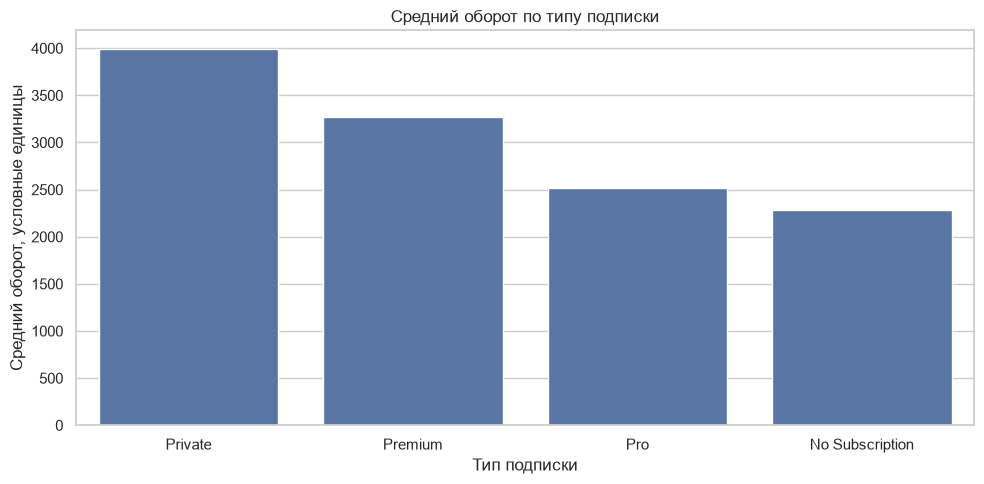

In [33]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=subscription_analysis,
    x="bundle_name",
    y="mean_gmv"
)

plt.title("Средний оборот по типу подписки")
plt.xlabel("Тип подписки")
plt.ylabel("Средний оборот, условные единицы")
plt.tight_layout()
plt.show()

## 2.9.1. Выводы по сравнению пользователей с разными подписками

Сравнение пользовательских метрик по типу подписки выявило различия в объёме использования топливного сервиса.

1. **Средний оборот увеличивается между основными категориями подписки.** Для пользователей без подписки он составляет 2 288,22 условной единицы, для Pro — 2 514,58, для Premium — 3 269,04. В категории Private средний оборот достигает 3 988,54, однако она представлена только 471 наблюдением и 119 уникальными клиентами, поэтому результат следует интерпретировать осторожно.

2. **Объём топлива также выше у пользователей с подпиской.** Средний показатель составляет 38,14 литра для пользователей без подписки, 41,35 литра для Pro и 51,05 литра для Premium. Для Private средний объём равен 57,50 литра.

3. **Количество заказов различается незначительно.** Среднее число заказов находится в диапазоне от 1,343 до 1,383 для пользователей без подписки, Pro и Premium. Для Private показатель составляет 1,257. Медиана во всех группах равна одному заказу в неделю.

4. **Количество посещений также отличается умеренно.** Среднее значение составляет 2,525 для пользователей без подписки, 2,638 для Pro, 2,582 для Premium и 2,459 для Private. Здесь нет последовательного роста показателя с повышением уровня подписки.

**Промежуточный вывод:** наиболее заметные различия между категориями подписки наблюдаются в среднем обороте и объёме топлива, тогда как количество заказов и посещений меняется значительно слабее. Это может указывать на различия в объёме покупок и составе клиентских групп, но не доказывает, что подписка сама по себе приводит к росту оборота. Для более надёжной интерпретации необходимо учитывать различия между клиентами и периодами наблюдения.

In [35]:
display(
    df["platform"]
    .value_counts(dropna=False)
    .rename_axis("platform")
    .reset_index(name="observations")
)

,platform,observations
0,ANDROID,216935
1,IOS,105540
2,WEBVIEW_IOS,80531
3,WEB,26907
4,WEBVIEW_ANDROID,18219


In [36]:
platform_analysis = (
    df.groupby("platform")
    .agg(
        observations=("party_rk", "size"),
        unique_clients=("party_rk", "nunique"),
        mean_orders=("orders_cnt", "mean"),
        mean_entries=("entries_cnt", "mean"),
        mean_gmv=("gmv", "mean"),
        median_gmv=("gmv", "median"),
        mean_liters=("liters", "mean"),
    )
    .reset_index()
    .sort_values("mean_gmv", ascending=False)
)

display(
    platform_analysis.style
    .hide(axis="index")
    .format({
        "observations": "{:,.0f}",
        "unique_clients": "{:,.0f}",
        "mean_orders": "{:.3f}",
        "mean_entries": "{:.3f}",
        "mean_gmv": "{:,.2f}",
        "median_gmv": "{:,.2f}",
        "mean_liters": "{:.2f}",
    })
)

platform,observations,unique_clients,mean_orders,mean_entries,mean_gmv,median_gmv,mean_liters
WEBVIEW_IOS,"80,531","24,971",1.388,1.552,"2,597.93","2,174.53",42.01
IOS,"105,540","28,389",1.374,2.987,"2,590.04","2,199.56",41.67
ANDROID,"216,935","52,008",1.355,2.965,"2,457.90","2,037.56",40.87
WEBVIEW_ANDROID,"18,219","6,703",1.403,1.722,"2,394.28","1,999.54",40.37
WEB,"26,907","18,953",1.281,1.509,"2,363.89","1,999.86",38.49


### 2.10.1. Выводы по сравнению платформ

Сравнение пользовательских метрик по платформам показало некоторые различия в активности и среднем обороте. Наибольший средний оборот наблюдается у WEBVIEW_IOS (2 597,93 условных единиц), немного ниже показатели IOS (2 590,04). Средний объём топлива также выше у WEBVIEW_IOS и IOS, чем у остальных платформ.

Наибольшее среднее количество заказов за неделю зафиксировано у WEBVIEW_ANDROID (1,403), тогда как у WEB оно составляет 1,281. При этом среднее количество посещений у IOS и ANDROID заметно выше, чем у WEB и веб-представлений приложения.

Результаты следует интерпретировать с учётом различий в размерах групп и возможных особенностей регистрации событий на разных платформах. Полученные различия являются описательными и сами по себе не доказывают, что платформа вызывает изменение пользовательского поведения.

In [38]:
weekly_fee_comparison = (
    df.groupby(["week_dt", "service_fee_amt"])
    .agg(
        observations=("party_rk", "size"),
        mean_orders=("orders_cnt", "mean"),
        mean_entries=("entries_cnt", "mean"),
        mean_gmv=("gmv", "mean"),
        mean_liters=("liters", "mean"),
    )
    .reset_index()
    .sort_values(["week_dt", "service_fee_amt"])
)

display(
    weekly_fee_comparison.head(30).style
    .hide(axis="index")
    .format({
        "service_fee_amt": "{:.0f}",
        "observations": "{:,.0f}",
        "mean_orders": "{:.3f}",
        "mean_entries": "{:.3f}",
        "mean_gmv": "{:,.2f}",
        "mean_liters": "{:.2f}",
    })
    .format({"week_dt": lambda x: x.strftime("%Y-%m-%d")})
)

week_dt,service_fee_amt,observations,mean_orders,mean_entries,mean_gmv,mean_liters
2025-03-30,0,9401,1.307095,2.926606,2214.921791,36.891747
2025-03-30,23,35065,1.264480,2.431887,2346.852177,38.615299
2025-03-30,69,26,5.115385,4.923077,10055.401154,165.932692
2025-04-06,0,7291,1.476066,2.978882,2423.368901,40.592504
2025-04-06,19,4569,1.284307,2.329851,2375.123259,39.039409
2025-04-06,23,5854,1.371370,2.463444,2504.894590,41.345690
2025-04-06,29,4789,1.345792,2.424223,2502.705176,41.026143
2025-04-06,39,4693,1.342212,2.398448,2555.580820,41.996631
2025-04-06,49,4442,1.316974,2.348858,2516.710840,41.402082
2025-04-06,59,4320,1.311806,2.360394,2464.601981,40.301025


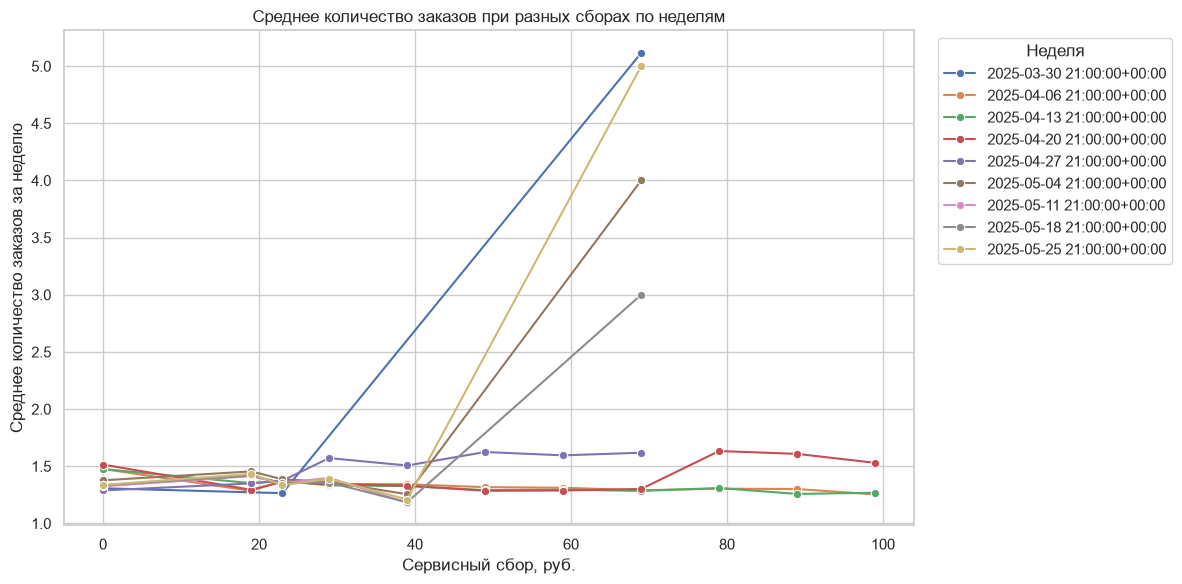

In [39]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_fee_comparison,
    x="service_fee_amt",
    y="mean_orders",
    hue="week_dt",
    marker="o",
    errorbar=None,
)

plt.title("Среднее количество заказов при разных сборах по неделям")
plt.xlabel("Сервисный сбор, руб.")
plt.ylabel("Среднее количество заказов за неделю")
plt.legend(title="Неделя", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

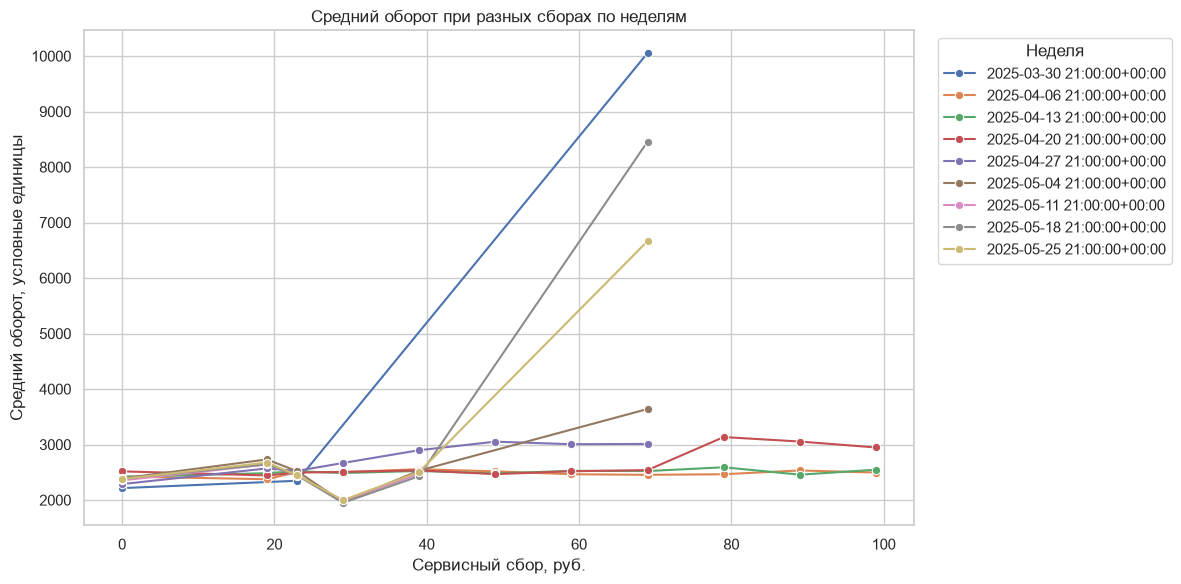

In [40]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_fee_comparison,
    x="service_fee_amt",
    y="mean_gmv",
    hue="week_dt",
    marker="o",
    errorbar=None,
)

plt.title("Средний оборот при разных сборах по неделям")
plt.xlabel("Сервисный сбор, руб.")
plt.ylabel("Средний оборот, условные единицы")
plt.legend(title="Неделя", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [41]:
small_groups = (
    weekly_fee_comparison[
        weekly_fee_comparison["observations"] < 1000
    ]
    .sort_values(["week_dt", "service_fee_amt"])
)

display(
    small_groups.style
    .hide(axis="index")
    .format({
        "service_fee_amt": "{:.0f}",
        "observations": "{:,.0f}",
        "mean_orders": "{:.3f}",
        "mean_entries": "{:.3f}",
        "mean_gmv": "{:,.2f}",
        "mean_liters": "{:.2f}",
    })
    .format({"week_dt": lambda x: x.strftime("%Y-%m-%d")})
)

week_dt,service_fee_amt,observations,mean_orders,mean_entries,mean_gmv,mean_liters
2025-03-30,69,26,5.115385,4.923077,10055.401154,165.932692
2025-04-20,79,357,1.633053,2.923513,3134.569076,51.198235
2025-04-20,89,347,1.608069,2.840116,3053.772075,50.017032
2025-04-20,99,319,1.529781,2.714734,2947.129279,48.655486
2025-05-04,69,2,4.000000,4.000000,3639.805000,90.550000
2025-05-18,69,1,3.000000,2.000000,8458.420000,119.950000
2025-05-25,29,986,1.389452,2.468172,1997.590852,33.418955
2025-05-25,69,2,5.000000,7.500000,6666.525000,125.950000


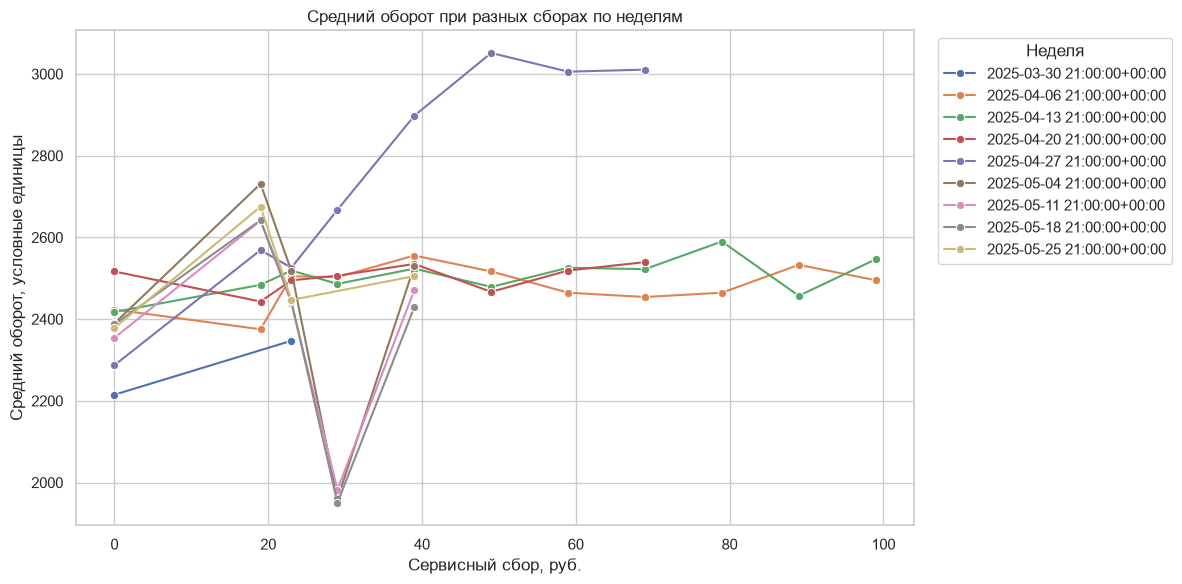

In [42]:
weekly_fee_comparison_filtered = weekly_fee_comparison[
    weekly_fee_comparison["observations"] >= 1000
].copy()

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_fee_comparison_filtered,
    x="service_fee_amt",
    y="mean_gmv",
    hue="week_dt",
    marker="o",
    errorbar=None,
)

plt.title("Средний оборот при разных сборах по неделям")
plt.xlabel("Сервисный сбор, руб.")
plt.ylabel("Средний оборот, условные единицы")
plt.legend(title="Неделя", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

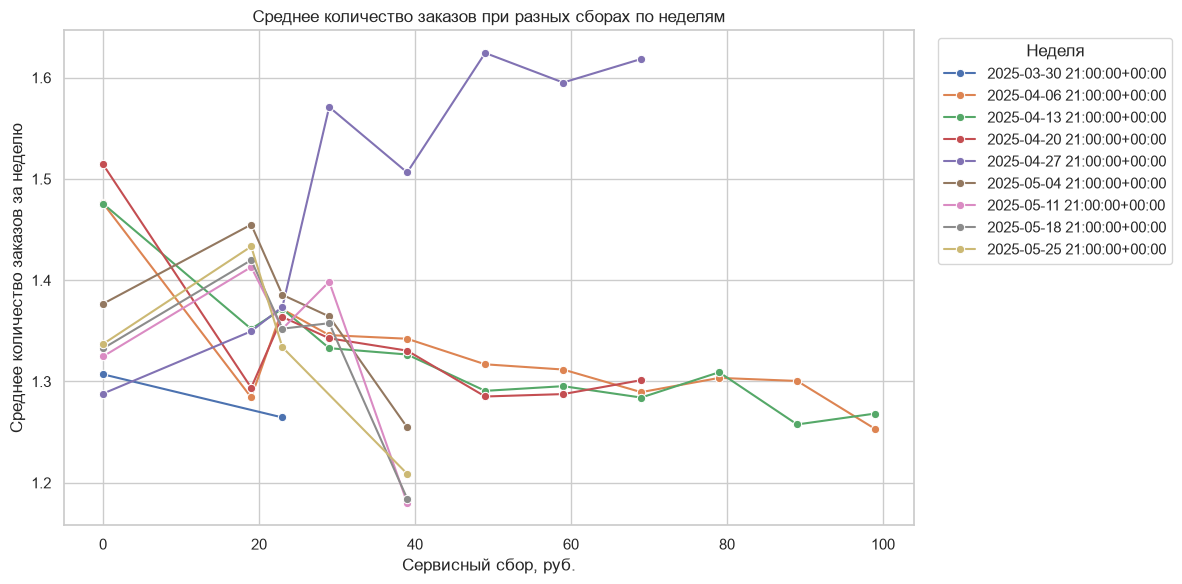

In [43]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=weekly_fee_comparison_filtered,
    x="service_fee_amt",
    y="mean_orders",
    hue="week_dt",
    marker="o",
    errorbar=None,
)

plt.title("Среднее количество заказов при разных сборах по неделям")
plt.xlabel("Сервисный сбор, руб.")
plt.ylabel("Среднее количество заказов за неделю")
plt.legend(title="Неделя", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 2.11. Промежуточные итоги исследовательского анализа

В ходе исследовательского анализа были изучены распределение сервисного сбора, динамика пользовательских показателей по неделям, различия между группами клиентов, а также связь размера сбора с количеством заказов, посещений, оборотом и объёмом топлива.

По результатам анализа можно сделать следующие выводы.

1. **Распределение сервисного сбора неоднородно.** Наиболее распространены сборы 0, 19 и 23 рубля. На группы с этими значениями приходится около 77% всех наблюдений. Высокие значения сбора встречаются значительно реже.

2. **Пользовательские показатели меняются во времени.** Средний размер сбора и показатели активности различаются между неделями. Поэтому сравнение клиентов за весь период без учёта времени может приводить к неоднозначным выводам.

3. **Простая зависимость между размером сбора и пользовательским поведением не обнаружена.** Корреляции сервисного сбора с количеством заказов, посещений, оборотом и объёмом топлива невелики по абсолютной величине. При сравнении групп также не наблюдается устойчивого монотонного снижения всех показателей с увеличением сбора.

4. **Внутри одного клиента показатели также не демонстрируют однозначной закономерности.** При сравнении наблюдений с разными сборами относительно среднего уровня конкретного клиента не выявлено последовательного изменения всех метрик по мере роста сбора.

5. **Между сегментами пользователей существуют различия.** Средний оборот и объём топлива отличаются в зависимости от подписки и платформы. Однако эти различия сами по себе не позволяют определить причины различий в поведении.

6. **Отдельные группы имеют небольшой размер, а некоторые показатели содержат экстремальные значения.** Это требует осторожности при интерпретации средних значений. На данном этапе наблюдения не удалялись из исходного набора данных.

Таким образом, описательный анализ выявил различия между группами и временными периодами, но не позволил установить, связан ли сервисный сбор с изменением поведения клиентов независимо от других факторов.

Поскольку данные являются наблюдательными, обнаруженные связи нельзя интерпретировать как доказательство причинно-следственного влияния. Для более содержательной проверки гипотез необходимо перейти от общего сравнения средних значений к анализу сопоставимых наблюдений с учётом временного периода и особенностей клиентов.

In [48]:
# Среднее количество заказов для каждой недели и размера сбора
orders_by_week_fee = (
    df.groupby(["week_dt", "service_fee_amt"])["orders_cnt"]
    .mean()
    .unstack("service_fee_amt")
)

# Сравниваем каждый сбор с 0 руб. внутри той же недели
orders_diff_by_week = (
    orders_by_week_fee
    .sub(orders_by_week_fee[0], axis=0)
    .drop(columns=0)
)

# Средняя разница по неделям
orders_diff_summary = pd.DataFrame({
    "mean_difference": orders_diff_by_week.mean(),
    "weeks_compared": orders_diff_by_week.count(),
})

display(orders_diff_summary.round(4))

,mean_difference,weeks_compared
service_fee_amt,,
19,-0.016,8
23,-0.029,9
29,-0.003,8
39,-0.099,8
49,-0.059,4
59,-0.066,4
69,1.438,8
79,-0.073,3
89,-0.100,3


In [49]:
orders_diff_by_week.round(3)

service_fee_amt,19,23,29,39,49,59,69,79,89,99
week_dt,,,,,,,,,,
2025-03-30 21:00:00+00:00,NaN,-0.043,NaN,NaN,NaN,NaN,3.808,NaN,NaN,NaN
2025-04-06 21:00:00+00:00,-0.192,-0.105,-0.130,-0.134,-0.159,-0.164,-0.187,-0.173,-0.176,-0.223
2025-04-13 21:00:00+00:00,-0.124,-0.104,-0.143,-0.149,-0.185,-0.180,-0.191,-0.166,-0.218,-0.207
2025-04-20 21:00:00+00:00,-0.221,-0.151,-0.172,-0.184,-0.229,-0.227,-0.213,0.119,0.094,0.015
2025-04-27 21:00:00+00:00,0.062,0.086,0.283,0.218,0.336,0.307,0.330,NaN,NaN,NaN
2025-05-04 21:00:00+00:00,0.078,0.009,-0.012,-0.122,NaN,NaN,2.623,NaN,NaN,NaN
2025-05-11 21:00:00+00:00,0.088,0.027,0.074,-0.144,NaN,NaN,NaN,NaN,NaN,NaN
2025-05-18 21:00:00+00:00,0.087,0.020,0.025,-0.148,NaN,NaN,1.667,NaN,NaN,NaN
2025-05-25 21:00:00+00:00,0.096,-0.003,0.053,-0.128,NaN,NaN,3.663,NaN,NaN,NaN


### 3.1. Проверка гипотезы H1: сервисный сбор и количество заказов

Для проверки гипотезы было проведено сравнение среднего количества заказов у одних и тех же клиентов в двух условиях: при нулевом и ненулевом сервисном сборе. Для сравнения использовался парный t-критерий Стьюдента.

В анализ вошли 34 703 клиента. Средняя разница между количеством заказов при ненулевом и нулевом сборе составила +0,0829 заказа в неделю. Значение t-статистики составило 25,511, p-value — 3,06 × 10⁻¹⁴².

Поскольку p-value меньше принятого уровня значимости 0,05, нулевая гипотеза об отсутствии средней разницы отвергается. Таким образом, в исследуемых данных выявлено статистически значимое различие в количестве заказов между двумя условиями.

Полученный результат не доказывает причинного влияния сервисного сбора на количество заказов. На различие могут влиять временные и другие факторы, а статистическая значимость не означает, что эффект велик с практической точки зрения.

In [52]:
from scipy.stats import ttest_rel

client_entries = (
    df.assign(
        fee_group=np.where(
            df["service_fee_amt"].eq(0),
            "zero",
            "positive"
        )
    )
    .groupby(["party_rk", "fee_group"])["entries_cnt"]
    .mean()
    .unstack()
    .dropna(subset=["zero", "positive"])
)

entries_diff = (
    client_entries["positive"] - client_entries["zero"]
)

entries_test = ttest_rel(
    client_entries["positive"],
    client_entries["zero"]
)

print(f"Количество клиентов: {len(entries_diff):,}")
print(f"Средняя разница: {entries_diff.mean():.4f}")
print(f"t-статистика: {entries_test.statistic:.3f}")
print(f"p-value: {entries_test.pvalue:.6g}")

Количество клиентов: 34,412
Средняя разница: -0.0639
t-статистика: -8.969
p-value: 3.13392e-19


### 3.2. Проверка гипотезы H2: сервисный сбор и количество посещений

Для проверки гипотезы было проведено сравнение среднего количества посещений у одних и тех же клиентов при нулевом и ненулевом сервисном сборе. Для сравнения использовался парный t-критерий Стьюдента.

В анализ вошли 34 412 клиентов. Средняя разница между количеством посещений при ненулевом и нулевом сборе составила −0,0639 посещения за неделю. Значение t-статистики составило −8,969, p-value — 3,13 × 10⁻¹⁹.

Поскольку p-value меньше уровня значимости 0,05, нулевая гипотеза об отсутствии средней разницы отвергается. В исследуемых данных обнаружено статистически значимое различие: при ненулевом сборе среднее количество посещений ниже.

При этом абсолютная величина различия невелика. Результат не доказывает причинного влияния сервисного сбора, поскольку наблюдаемые различия могут быть связаны с временными и другими факторами.

In [53]:
from scipy.stats import ttest_rel

client_metrics = (
    df.assign(
        fee_group=np.where(
            df["service_fee_amt"].eq(0),
            "zero",
            "positive"
        )
    )
    .groupby(["party_rk", "fee_group"])[["gmv", "liters"]]
    .mean()
    .unstack("fee_group")
)

results = []

for metric in ["gmv", "liters"]:
    zero = client_metrics[(metric, "zero")]
    positive = client_metrics[(metric, "positive")]

    paired = pd.concat(
        [zero.rename("zero"), positive.rename("positive")],
        axis=1
    ).dropna()

    test = ttest_rel(paired["positive"], paired["zero"])

    results.append({
        "metric": metric,
        "clients": len(paired),
        "mean_difference": (paired["positive"] - paired["zero"]).mean(),
        "t_statistic": test.statistic,
        "p_value": test.pvalue,
    })

h3_results = pd.DataFrame(results)
display(h3_results.round(4))

,metric,clients,mean_difference,t_statistic,p_value
0,gmv,34703,187.655,23.560,0.000
1,liters,34703,3.201,26.053,0.000


### 3.3. Проверка гипотезы H3: сервисный сбор, оборот и объём топлива

Для проверки гипотезы было проведено парное сравнение среднего GMV и объёма топлива у одних и тех же клиентов при нулевом и ненулевом сервисном сборе. Для обоих показателей использовался парный t-критерий Стьюдента.

В анализ вошли 34 703 клиента.

Для GMV средняя разница составила +187,655 условных единиц, t-статистика — 23,560. Для объёма топлива средняя разница составила +3,201 литра, t-статистика — 26,053. В обоих случаях p-value значительно меньше уровня значимости 0,05.

Таким образом, нулевая гипотеза об отсутствии средней разницы отвергается для обоих показателей. В исследуемых данных при ненулевом сборе наблюдаются более высокие средние значения оборота и объёма топлива.

Результаты показывают статистическую связь, но не доказывают причинного влияния сервисного сбора. На различия могут влиять особенности клиентов, временные факторы и состав наблюдений в сравниваемых группах.

In [54]:
from scipy.stats import ttest_ind

# Для каждой комбинации клиента и подписки сравниваем
# средний GMV при нулевом и ненулевом сборе
client_segment_gmv = (
    df.assign(
        fee_group=np.where(
            df["service_fee_amt"].eq(0),
            "zero",
            "positive"
        )
    )
    .groupby(["party_rk", "bundle_name", "fee_group"])["gmv"]
    .mean()
    .unstack("fee_group")
    .dropna(subset=["zero", "positive"])
    .reset_index()
)

# Разница GMV для каждого клиента в каждом сегменте
client_segment_gmv["gmv_difference"] = (
    client_segment_gmv["positive"]
    - client_segment_gmv["zero"]
)

# Сводка по сегментам
segment_summary = (
    client_segment_gmv
    .groupby("bundle_name")
    .agg(
        clients=("party_rk", "nunique"),
        mean_difference=("gmv_difference", "mean"),
        median_difference=("gmv_difference", "median"),
        std_difference=("gmv_difference", "std")
    )
    .sort_values("clients", ascending=False)
)

display(segment_summary.round(3))

,clients,mean_difference,median_difference,std_difference
bundle_name,,,,
No Subscription,15858,166.654,49.180,"1,179.265"
Pro,13532,176.387,59.002,"1,306.817"
Premium,4443,328.240,127.135,"2,668.915"
Private,76,250.650,18.151,"1,954.186"


In [55]:
from itertools import combinations
from scipy.stats import ttest_ind
import pandas as pd

main_segments = [
    "No Subscription",
    "Pro",
    "Premium"
]

segment_tests = []

for segment_a, segment_b in combinations(main_segments, 2):
    values_a = client_segment_gmv.loc[
        client_segment_gmv["bundle_name"] == segment_a,
        "gmv_difference"
    ].dropna()

    values_b = client_segment_gmv.loc[
        client_segment_gmv["bundle_name"] == segment_b,
        "gmv_difference"
    ].dropna()

    test = ttest_ind(
        values_a,
        values_b,
        equal_var=False
    )

    segment_tests.append({
        "segment_1": segment_a,
        "segment_2": segment_b,
        "mean_difference_1": values_a.mean(),
        "mean_difference_2": values_b.mean(),
        "difference_between_segments": values_b.mean() - values_a.mean(),
        "p_value": test.pvalue
    })

segment_tests_df = pd.DataFrame(segment_tests)

display(segment_tests_df.round(4))

,segment_1,segment_2,mean_difference_1,mean_difference_2,difference_between_segments,p_value
0,No Subscription,Pro,166.654,176.387,9.732,0.506
1,No Subscription,Premium,166.654,328.240,161.586,0.000
2,Pro,Premium,176.387,328.240,151.853,0.000


### 3.4. Проверка гипотезы H4: различия между сегментами подписки

Для проверки гипотезы клиенты были разделены на сегменты по типу подписки. Для каждого клиента рассчитывалась разница между средним GMV при ненулевом и нулевом сервисном сборе. Затем эти разницы сравнивались между сегментами с помощью t-критерия Уэлча.

В основных сегментах получены следующие средние разницы GMV:
- No Subscription — 166,654 условных единиц;
- Pro — 176,387 условных единиц;
- Premium — 328,240 условных единиц.

Между сегментами No Subscription и Pro статистически значимого различия не обнаружено (p = 0,506). В сегменте Premium средняя разница оказалась выше, чем в No Subscription, на 161,586 условных единиц и выше, чем в Pro, на 151,853 условных единиц. Оба различия статистически значимы даже после поправки Бонферрони на три сравнения.

Таким образом, результаты согласуются с гипотезой о различиях между сегментами подписки: у клиентов Premium наблюдается более высокая разница среднего GMV между периодами с ненулевым и нулевым сбором. При этом статистическая связь не доказывает причинного влияния сбора или подписки на оборот.

Результат для сегмента Private отдельно не интерпретировался из-за малого размера группы (76 клиентов).

## 4. Итоги проверки гипотез

В ходе исследования были проверены четыре гипотезы о связи сервисного сбора с поведением клиентов.

| Гипотеза | Результат | Интерпретация |
|---|---|---|
| H1. Сервисный сбор связан с количеством заказов | Подтверждена статистическая связь | При ненулевом сборе среднее количество заказов выше на 0,0829 |
| H2. Сервисный сбор связан с количеством посещений | Подтверждена статистическая связь | При ненулевом сборе среднее количество посещений ниже на 0,0639 |
| H3. Сервисный сбор связан с GMV и объёмом топлива | Подтверждена статистическая связь | При ненулевом сборе средний GMV выше на 187,655 условных единиц, а объём топлива — на 3,201 литра |
| H4. Связь с GMV различается между сегментами подписки | Частично подтверждена | Для Premium разница GMV выше, чем для Pro и No Subscription; между последними двумя сегментами значимого различия не выявлено |

Подтверждение статистической связи не означает, что сервисный сбор является причиной обнаруженных различий.

## 5. Основные выводы

По результатам анализа можно сформулировать следующие выводы.

1. **Количество заказов.** Среднее количество заказов на клиента в наблюдениях с ненулевым сбором оказалось выше, чем в наблюдениях с нулевым сбором. Обнаруженная разница статистически значима, но сама по себе не доказывает положительного влияния сбора на активность клиентов.

2. **Количество посещений.** При ненулевом сборе среднее количество посещений оказалось ниже. Это может указывать на различия в поведении клиентов, однако величина разницы невелика, а её причины по имеющимся данным установить нельзя.

3. **GMV и объём топлива.** В наблюдениях с ненулевым сбором средние значения GMV и объёма топлива оказались выше. Следовательно, в данных не наблюдается простого сценария, при котором ненулевой сбор обязательно сопровождается снижением этих показателей.

4. **Различия между подписками.** Наибольшая средняя разница GMV между наблюдениями с нулевым и ненулевым сбором обнаружена у клиентов Premium. Различия между Premium и двумя другими основными сегментами статистически значимы даже после поправки Бонферрони.

5. **Необходимость осторожной интерпретации.** Направление различий неодинаково для разных метрик. Поэтому нельзя сделать общий вывод, что ненулевой сбор однозначно улучшает или ухудшает поведение клиентов.

## 6. Ограничения исследования

При интерпретации результатов необходимо учитывать несколько ограничений.

1. **Наблюдательный характер данных.** В данных отсутствует контролируемый эксперимент с случайным распределением клиентов по условиям. Поэтому выявленные различия нельзя трактовать как доказательство причинного влияния сервисного сбора.

2. **Изменение сбора во времени.** Размер сбора менялся в течение исследуемого периода. Одновременно могли меняться другие условия обслуживания и поведение клиентов, поэтому часть различий может быть связана с временными факторами.

3. **Повторные наблюдения.** Один клиент мог присутствовать в данных в течение нескольких недель. Парное сравнение средних показателей клиента частично учитывает индивидуальные особенности, однако не устраняет влияние времени и других изменяющихся факторов.

4. **Неодинаковые размеры сегментов.** Количество клиентов в сегментах подписки различается. В частности, сегмент Private представлен значительно слабее основных сегментов, поэтому делать по нему уверенные выводы нельзя.

5. **Статистическая значимость и практическая значимость.** При большой выборке даже небольшие различия могут быть статистически значимыми. Поэтому результаты следует оценивать не только по p-value, но и по величине обнаруженной разницы.

6. **Множественные проверки.** В исследовании проверялось несколько гипотез. Для трёх попарных сравнений сегментов подписки применена поправка Бонферрони. Остальные результаты следует рассматривать с учётом того, что при множественных проверках возрастает вероятность случайно обнаружить статистически значимую связь.

## 7. Итоговая интерпретация результатов

### Основные наблюдения

Проведённый анализ не выявил однозначной картины ухудшения поведения клиентов при ненулевом сервисном сборе. Напротив, в исследуемых данных при ненулевом сборе наблюдались более высокие средние значения GMV, объёма топлива и количества заказов. При этом среднее количество посещений было немного ниже.

Это позволяет предположить, что разные показатели поведения клиентов могут реагировать на изменение условий обслуживания неодинаково. Например, снижение частоты посещений не обязательно сопровождается снижением оборота. Однако имеющиеся результаты не позволяют подтвердить конкретный механизм такого поведения.

### Различия между сегментами клиентов

Наиболее заметное различие обнаружено в сегменте Premium. Средняя разница GMV между наблюдениями с ненулевым и нулевым сбором составила 328,24 условных единицы, тогда как для Pro она составила 176,39, а для клиентов без подписки — 166,65.

Попарные сравнения показали статистически значимые различия между Premium и двумя другими основными сегментами. Между Pro и клиентами без подписки статистически значимого различия не обнаружено.

Этот результат указывает на необходимость отдельно изучать поведение клиентов Premium. При этом он не доказывает, что подписка снижает чувствительность клиентов к сервисному сбору: различия могут объясняться исходными особенностями клиентских групп.

### Практическое значение для бизнеса

Полученные результаты позволяют сформулировать несколько направлений для дальнейшего анализа:

- Оценивать сервисный сбор по совокупности показателей, включая количество заказов, посещений, GMV и объём топлива.
- Отдельно изучить поведение клиентов Premium и выяснить, какие характеристики могут объяснять обнаруженные различия.
- Проверить, сохраняются ли выявленные связи после учёта временных факторов и изменений размера сбора.

На основании текущего анализа нельзя рекомендовать повышение или снижение сервисного сбора. Для такого решения необходимо оценить причинное влияние сбора на поведение клиентов.

### Ограничения интерпретации

Исследование основано на наблюдательных данных за девять недель. Размер сервисного сбора менялся во времени, поэтому выявленные различия могут быть связаны не только со сбором, но и с другими временными факторами.

Парное сравнение показателей одних и тех же клиентов позволяет частично учитывать постоянные индивидуальные особенности, однако не устраняет влияние изменений во времени. Кроме того, статистическая значимость различий сама по себе не означает, что они имеют существенное практическое значение.

GMV в исходных данных выражен в условных единицах, поэтому его нельзя напрямую интерпретировать как фактическую выручку в рублях.

### Итоговый вывод

В рамках исследования были обнаружены статистически значимые связи между наличием ненулевого сервисного сбора и рядом показателей поведения клиентов. Также выявлены различия в разнице GMV между сегментами подписки, наиболее заметные для Premium.

При этом результаты не подтверждают причинного влияния сервисного сбора на поведение клиентов.